# fedOPD — build the canonical table

Transformation only. Reads the 96 validated monthly RTT extracts and produces **one** tidy table at **provider × department × month**, plus the rectangular panel the federation trains on.

Run after `inspect_dataset.ipynb`, which establishes the facts relied on here.

## What this builds

**19 series per provider:** the 18 named specialties that span all 96 months, plus `X_OTHER`, a merged residual worth about a quarter of demand.

**All providers retained**, trust and independent alike, with a `sector` column. Sector filtering is a downstream one-line panel decision, never baked in here.

**14 columns out of 121.** A raw column is kept only if some part of the README's system consumes it. The column contract, and the measurement justifying every drop, is the section before the outputs.

## The two era reconciliations

NHS England changed the return in April 2021 in two independent ways, both the same shape — coarse before, finer after. Both reconcile to the **coarser** form, because the early era cannot be disaggregated.

| | pre-2021 | post-2021 | reconciled to |
|---|---|---|---|
| Long waits | single `Gt 52 Weeks` column | weekly bands 52→104 plus `Gt 104` | one `>52` figure |
| Residual specialties | single `X01 Other` | five buckets `X02`–`X06` | one `X_OTHER` series |

Columns are chosen **by name with an explicit era branch**, never by position.

## Standing asserts

Every trap found during inspection fails loudly here rather than silently:

1. **Full-coverage identity** — 18 named + `X_OTHER` = `C_999`, per provider, part type and month.
2. **Boundary continuity at 2021-04** — measured against *local* variation, not global.
3. **Code-only joins** — treatment functions keyed on code; names changed at the break, codes did not.
4. **Key uniqueness** — one row per provider × department × month.
5. **Hierarchy completeness** — every panel trust resolves to an ICB, so escalation has a target.
6. **Round trip** — the written parquet reads back with the same shape and a real datetime index.

In [1]:
import re                                         # parse the month and band edges out of names
from pathlib import Path                          # filesystem paths
from datetime import datetime                     # sortable month keys

import pandas as pd                               # all tabular work
import matplotlib.pyplot as plt                   # the continuity plots

DATA = Path("../data")
RTT_CSV = DATA / "rtt_csv"                        # the 96 validated monthly files
REF = DATA / "reference"                          # census + lookups from inspect_dataset
OUT = DATA / "canonical"                          # everything this notebook produces
OUT.mkdir(parents=True, exist_ok=True)            # no-op if it already exists

AGG = "C_999"                                     # published aggregate row — never a department
OTHER = "X_OTHER"                                 # our merged residual series
ERA = datetime(2021, 4, 1)                        # first month of the post-change schema

MONTHS = "JANUARY FEBRUARY MARCH APRIL MAY JUNE JULY AUGUST SEPTEMBER OCTOBER NOVEMBER DECEMBER".split()

def month_of(name):
    """'RTT-OCTOBER-2019-full-extract.csv' -> datetime(2019, 10, 1)."""
    m = re.search(r"(" + "|".join(MONTHS) + r")-(\d{4})", name.upper())   # month word + year
    return datetime(int(m.group(2)), MONTHS.index(m.group(1)) + 1, 1)     # index+1 = month number

csvs = sorted(RTT_CSV.glob("*.csv"), key=lambda p: month_of(p.name))      # chronological order
census = pd.read_csv(REF / "provider_census.csv")                        # built by inspect_dataset
SECTOR = dict(zip(census.code, census.sector))                           # code -> public/independent
ICB = dict(zip(census.code, census.icb_parent))                          # code -> ICB where one exists
PANEL = set(census[census.panel_member].code)                            # the 126 balanced-panel trusts
print(f"{len(csvs)} monthly files | {len(census)} providers | {len(PANEL)} panel trusts")

96 monthly files | 653 providers | 126 panel trusts


## Helpers

Four small functions carry every era-dependent decision, so the branch lives in one visible place instead of being scattered through the build.

In [2]:
def week_of(col):
    """Lower edge of a band column. 'Gt 18 To 19 Weeks SUM 1' -> 18, 'Gt 104 Weeks SUM 1' -> 104."""
    return int(re.match(r"Gt (\d+)", col).group(1))           # the first number in the name

def bands_from(cols, lo):
    """Band columns at or above `lo` weeks, selected BY NAME so both eras work unchanged:
       pre-2021,  lo=52 -> ['Gt 52 Weeks SUM 1']           the single open-ended bucket
       post-2021, lo=52 -> ['Gt 52 To 53', ..., 'Gt 104']  weekly bands plus the tail
       The 18-52 bands are identical in both eras, so lo=18 needs no branch at all."""
    return [c for c in cols if "Weeks SUM" in c               # waiting-time band columns only
            and week_of(c) >= lo]                             # at or above the threshold

def dept_of(code):
    """Treatment-function code -> series name. X01..X06 all collapse into one residual."""
    return OTHER if str(code).startswith("X") else code       # named specialties pass through

def header_of(path):
    """Column names of a csv, without reading the body."""
    return open(path, newline="").readline().rstrip("\r\n").replace('"', "").split(",")

# print what the rule selects in each era, so the branch is visible rather than implied
for label, f in [("pre-2021", csvs[0]), ("post-2021", csvs[-1])]:
    cols = header_of(f)                                       # this month's schema
    g52 = bands_from(cols, 52)                                # the era-dependent set
    print(f"{label:10s} >18 uses {len(bands_from(cols, 18)):3d} cols | "
          f">52 uses {len(g52):3d} cols -> {g52[0]}{' ... ' + g52[-1] if len(g52) > 1 else ''}")

pre-2021   >18 uses  35 cols | >52 uses   1 cols -> Gt 52 Weeks SUM 1
post-2021  >18 uses  87 cols | >52 uses  53 cols -> Gt 52 To 53 Weeks SUM 1 ... Gt 104 Weeks SUM 1


## The build pass

One read of all 96 files. Band columns are read **only for `Part_2`**, the waiting list — the only part type whose long-wait detail is used. Reading bands for the other four would multiply the IO for columns we then discard.

This is the slow cell.

In [3]:
KEYS = ["Provider Org Code", "Provider Org Name", "Provider Parent Org Code",
        "RTT Part Type", "Treatment Function Code", "Total All"]      # always needed

totals, longwaits, coverage = [], [], []          # three small frames per month, concatenated after
for p in csvs:
    mth = month_of(p.name)                        # this file's month
    cols = header_of(p)                           # this file's schema, 69 or 121 columns
    g18 = bands_from(cols, 18)                    # >18w columns, era-stable
    g52 = bands_from(cols, 52)                    # >52w columns, era-dependent
    d = pd.read_csv(p, usecols=lambda c: c in set(KEYS) | set(g18), low_memory=False)

    # --- coverage input: set the published C_999 rows aside, then drop them from the data ---
    is_agg = d["Treatment Function Code"].eq(AGG)                      # the aggregate rows
    published = (d[is_agg].groupby(["Provider Org Code", "RTT Part Type"])["Total All"]
                          .sum().rename("published"))                  # what NHS says the total is
    d = d[~is_agg].copy()                                              # real specialties only
    d["dept"] = d["Treatment Function Code"].map(dept_of)              # X01..X06 -> X_OTHER

    ours = (d.groupby(["Provider Org Code", "RTT Part Type"])["Total All"]
             .sum().rename("ours"))                                    # what our 19 series sum to
    chk = pd.concat([published, ours], axis=1).fillna(0).reset_index()
    chk["month"] = mth
    coverage.append(chk)                                               # checked by Assert 1

    # --- headline totals: one value per provider x dept x part type ---
    t = (d.groupby(["Provider Org Code", "Provider Org Name",
                    "Provider Parent Org Code", "dept", "RTT Part Type"])["Total All"]
          .sum().rename("total").reset_index())
    t["month"] = mth
    totals.append(t)

    # --- long waits: Part_2 only, because only the waiting list needs band detail ---
    w = d[d["RTT Part Type"] == "Part_2"]                              # incomplete pathways
    lw = pd.DataFrame({
        "Provider Org Code": w["Provider Org Code"],
        "dept": w["dept"],
        "waiting_gt18": w[g18].fillna(0).sum(axis=1),                  # sum the >=18w bands
        "waiting_gt52": w[g52].fillna(0).sum(axis=1),                  # era-reconciled >=52w
    })
    lw = lw.groupby(["Provider Org Code", "dept"]).sum().reset_index() # collapse to the key
    lw["month"] = mth
    longwaits.append(lw)

totals = pd.concat(totals, ignore_index=True)                          # one row per part type
longwaits = pd.concat(longwaits, ignore_index=True)
coverage = pd.concat(coverage, ignore_index=True)
print(f"{len(totals):,} provider x dept x part x month rows | {len(longwaits):,} long-wait rows")

1,421,475 provider x dept x part x month rows | 317,768 long-wait rows


## Assert 1 — full-coverage identity

18 named + `X_OTHER` must equal the published `C_999`, for every provider, part type and month. Stronger than the roster-drift check in `inspect_dataset.ipynb`: it proves the 19 series account for **all** reported activity, so the hierarchy reconciles exactly rather than approximately.

In [4]:
coverage["diff"] = coverage["ours"] - coverage["published"]    # zero everywhere if coverage is total
bad = coverage[coverage["diff"].abs() > 0.5]                   # tolerance for float noise only
print(f"groups compared : {len(coverage):,}")
print(f"mismatched      : {len(bad)}")
if len(bad):
    print(bad.head(15).to_string(index=False))                 # show exactly what broke
assert len(bad) == 0, "the 19 series do not reproduce C_999 — coverage is incomplete"
print("\nASSERT 1 PASSED: 18 named + X_OTHER = C_999 everywhere. Coverage is total.")

groups compared : 199,410
mismatched      : 0

ASSERT 1 PASSED: 18 named + X_OTHER = C_999 everywhere. Coverage is total.


## Assemble the canonical table

Pivot the five part types into columns, attach the long-wait detail, then the census flags.

In [5]:
IDX = ["month", "Provider Org Code", "Provider Org Name", "Provider Parent Org Code", "dept"]

# pivot_table reshapes long -> wide: each distinct value of `columns` becomes its own column,
# so the five RTT part types stop being rows and become five measures on one key.
# fill_value=0 makes an unreported combination read as no activity rather than NaN.
wide = totals.pivot_table(index=IDX, columns="RTT Part Type", values="total",
                          fill_value=0).reset_index()
wide.columns.name = None                                       # drop the pivot's column-axis label

canon = wide.rename(columns={
    "Provider Org Code": "provider_code",
    "Provider Org Name": "provider_name",
    "Provider Parent Org Code": "icb_reported",                 # parent as stated in the RTT file
    "Part_3": "demand",                                         # new RTT periods = demand signal
    "Part_1A": "completed_admitted",                            # completed pathways, admitted
    "Part_1B": "completed_nonadmitted",                         # completed pathways, non-admitted
    "Part_2": "waiting",                                        # incomplete pathways = waiting list
    "Part_2A": "waiting_dta",                                   # of those, with a decision to admit
})

# attach >18w / >52w detail; how="left" keeps every canonical row, and rows with no matching
# long-wait record come back NaN, which means zero long waits
canon = canon.merge(longwaits.rename(columns={"Provider Org Code": "provider_code"}),
                    on=["month", "provider_code", "dept"], how="left")
canon[["waiting_gt18", "waiting_gt52"]] = canon[["waiting_gt18", "waiting_gt52"]].fillna(0)

canon["completed"] = canon.completed_admitted + canon.completed_nonadmitted   # total throughput
canon["sector"] = canon.provider_code.map(SECTOR)               # public / independent
canon["icb_ods"] = canon.provider_code.map(ICB)                 # ODS RE5 parent, time-invariant
canon["panel_member"] = canon.provider_code.isin(PANEL)         # flag, never a filter

# --- the escalation key -------------------------------------------------------------------
# `icb_reported` is NOT a usable ICB key. It is whatever parent organisation the RTT file
# named that month: 14 distinct values in 2018-19 (NHS regions), 42 from 2020 (ICBs). Using
# it would silently mix two levels of the hierarchy across the window — measured in the
# column contract section below. `icb_ods` is one fixed ICB per trust, so that is the key.
canon["icb"] = canon.icb_ods                                    # authoritative where ODS resolved it
gap = canon.sector.eq("public") & canon.icb.isna()              # public providers ODS could not place
canon.loc[gap, "icb"] = canon.loc[gap, "icb_reported"]          # fall back to the file's own parent
print(f"icb backfilled from icb_reported for "
      f"{canon.loc[gap, 'provider_code'].nunique()} public providers ({int(gap.sum()):,} rows); "
      f"independents keep icb = NaN, they have no commissioner parent")

canon = canon.sort_values(["provider_code", "dept", "month"]).reset_index(drop=True)

# --- apply the column contract --------------------------------------------------------------
# Everything per-provider rather than per-row moves to a dimension table: it is one value per
# code repeated across up to 1,824 rows, and a name is a label, never a join key (F-11).
provider_dim = (canon.sort_values("month").groupby("provider_code").agg(
    provider_name=("provider_name", "last"),                    # most recent spelling
    sector=("sector", "first"),
    icb=("icb", "first"),
    icb_ods=("icb_ods", "first"),                               # provenance: what ODS said
    icb_reported_last=("icb_reported", "last"),                 # provenance: what the file said
    panel_member=("panel_member", "first"),
    first_month=("month", "min"), last_month=("month", "max"),
).reset_index())

# keep the month-varying reported parent alive for the contract evidence below, then drop it
icb_audit = canon[["month", "sector", "icb_reported", "icb_ods"]].copy()

KEEP = ["month", "provider_code", "dept", "sector", "icb", "panel_member",
        "demand", "completed_admitted", "completed_nonadmitted", "completed",
        "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]
dropped = [c for c in canon.columns if c not in KEEP]
canon = canon[KEEP]
print(f"columns dropped to the dimension table / derivable: {dropped}")

# Assert 4 — the key must be unique
dup = int(canon.duplicated(["provider_code", "dept", "month"]).sum())
assert dup == 0, f"{dup} duplicate provider/dept/month rows"
# Assert 5 — every federation client must have somewhere to escalate to
orphan = canon[canon.panel_member & canon.icb.isna()].provider_code.nunique()
assert orphan == 0, f"{orphan} panel trusts have no ICB — the hierarchy is broken"

print(f"canonical rows : {len(canon):,}  x {len(canon.columns)} columns")
print(f"providers      : {canon.provider_code.nunique()}")
print(f"departments    : {canon.dept.nunique()}  (18 named + {OTHER})")
print(f"months         : {canon.month.nunique()}")
print(f"ICBs (key)     : {canon.icb.nunique()} | panel trusts with no ICB: {orphan}")
canon.head()

icb backfilled from icb_reported for 16 public providers (3,522 rows); independents keep icb = NaN, they have no commissioner parent


columns dropped to the dimension table / derivable: ['provider_name', 'icb_reported', 'icb_ods']
canonical rows : 322,531  x 14 columns
providers      : 653
departments    : 19  (18 named + X_OTHER)
months         : 96
ICBs (key)     : 47 | panel trusts with no ICB: 0


,month,provider_code,dept,sector,icb,panel_member,demand,completed_admitted,completed_nonadmitted,completed,waiting,waiting_gt18,waiting_gt52,waiting_dta
0,2024-06-01,8KL73,C_301,independent,NaN,False,139.0,101.0,0.0,101.0,70.0,0.0,0.0,70.0
1,2024-07-01,8KL73,C_301,independent,NaN,False,141.0,130.0,0.0,130.0,55.0,0.0,0.0,55.0
2,2024-08-01,8KL73,C_301,independent,NaN,False,122.0,129.0,0.0,129.0,51.0,0.0,0.0,51.0
3,2020-12-01,A0C5S,C_130,independent,NaN,False,2.0,0.0,1.0,1.0,7.0,0.0,0.0,0.0
4,2021-01-01,A0C5S,C_130,independent,NaN,False,23.0,4.0,5.0,9.0,35.0,0.0,0.0,12.0


## Assert 2 — boundary continuity at 2021-04

Both reconciliations must be invisible in the joined series. The comparison uses **local** variation — the months either side of the break — not a global dispersion statistic. The `>52` series sits near zero through the whole pre-covid period, so a global median is dominated by quiet months and would make any step at a turbulent join look like a discontinuity when it is not.

In [6]:
def boundary_ratio(series, window=6):
    """Step at the era join, expressed in units of LOCAL month-to-month variation."""
    s = series.sort_index()
    prev = pd.Timestamp(ERA) - pd.offsets.MonthBegin(1)        # last pre-change month
    step = s.loc[ERA] - s.loc[prev]                            # the join step being judged
    diffs = s.diff().abs()                                     # every month-to-month change
    lo = pd.Timestamp(ERA) - pd.offsets.MonthBegin(window)     # window months before
    hi = pd.Timestamp(ERA) + pd.offsets.MonthBegin(window)     # window months after
    local = diffs.loc[lo:hi].drop(index=ERA).median()          # exclude the step from its own yardstick
    return step, local, abs(step) / local

other_demand = canon[canon.dept == OTHER].groupby("month").demand.sum()    # the merged residual
gt52_waiting = canon.groupby("month").waiting_gt52.sum()                   # reconciled long waits

for label, s in [("X_OTHER demand", other_demand), (">52 waiting", gt52_waiting)]:
    step, local, ratio = boundary_ratio(s)
    print(f"{label:16s} step {step:>12,.0f}   local |change| {local:>12,.0f}   ratio {ratio:.2f}x")
    assert ratio < 3, f"{label} steps at the era boundary — the reconstruction is wrong"
print("\nASSERT 2 PASSED: neither reconstruction introduces a step at 2021-04.")

X_OTHER demand   step      -27,874   local |change|       18,442   ratio 1.51x
>52 waiting      step      -50,024   local |change|       29,700   ratio 1.68x

ASSERT 2 PASSED: neither reconstruction introduces a step at 2021-04.


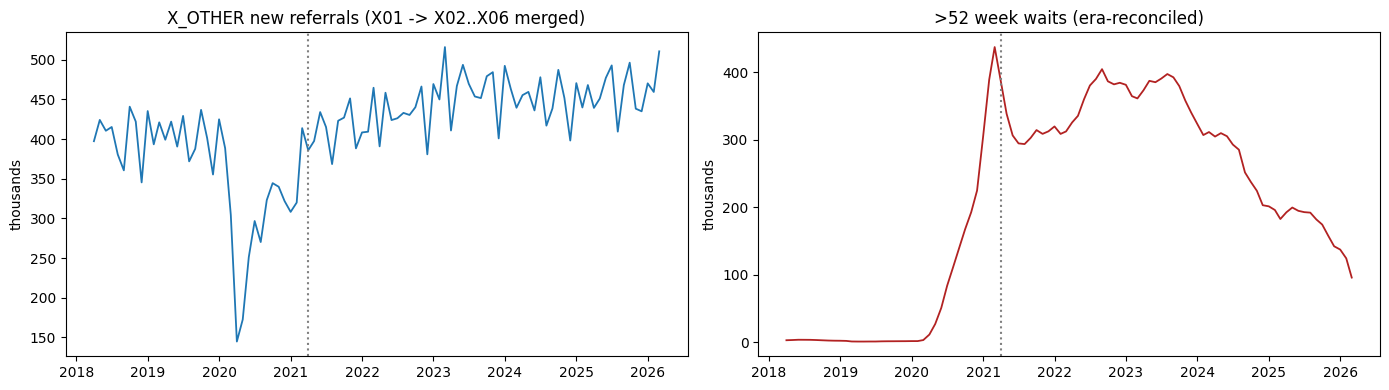

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(other_demand.index, other_demand / 1e3, lw=1.3)
ax[0].axvline(ERA, color="grey", ls=":")                       # the recode boundary
ax[0].set_title("X_OTHER new referrals (X01 -> X02..X06 merged)")
ax[0].set_ylabel("thousands")
ax[1].plot(gt52_waiting.index, gt52_waiting / 1e3, lw=1.3, color="firebrick")
ax[1].axvline(ERA, color="grey", ls=":")                       # same boundary, other reconciliation
ax[1].set_title(">52 week waits (era-reconciled)")
ax[1].set_ylabel("thousands")
plt.tight_layout()

## The panel cube

The federation trains on a rectangular 126 × 19 × 96 cube. Cells absent from the source are filled with zero, but **most of that fill is structural** — a trust that does not provide neurosurgery has no neurosurgery rows, ever. Those series are counted and flagged here so phase 3 can exclude them in one line instead of training on constant zeros.

In [8]:
MEASURES = ["demand", "completed_admitted", "completed_nonadmitted", "completed",
            "waiting", "waiting_gt18", "waiting_gt52", "waiting_dta"]

# from_product builds every combination of the given lists, which is how a ragged table is
# made rectangular: this is every (trust, dept, month) cell a balanced panel should contain
full = pd.MultiIndex.from_product(
    [sorted(PANEL), sorted(canon.dept.unique()), sorted(canon.month.unique())],
    names=["provider_code", "dept", "month"])

panel = (canon[canon.panel_member]                             # panel trusts only
         .set_index(["provider_code", "dept", "month"])
         .reindex(full))                                       # absent combinations become NaN rows
filled = int(panel.demand.isna().sum())                        # how many cells were absent
panel[MEASURES] = panel[MEASURES].fillna(0)                    # absent = no activity = 0
panel = panel.reset_index()
panel["sector"] = "public"                                     # public by construction
panel["panel_member"] = True                                   # ditto — reindex left NaN on new rows
panel["icb"] = panel.provider_code.map(                        # re-attach the key the new rows lack
    dict(zip(provider_dim.provider_code, provider_dim.icb)))

print(f"panel cube : {len(panel):,} rows = {len(PANEL)} trusts x "
      f"{panel.dept.nunique()} depts x {panel.month.nunique()} months")
print(f"cells filled with zero : {filled:,} ({filled / len(panel) * 100:.2f}% of the cube)")
assert panel.icb.notna().all(), "panel rows without an ICB — the escalation key has holes"

panel cube : 229,824 rows = 126 trusts x 19 depts x 96 months
cells filled with zero : 62,313 (27.11% of the cube)


In [9]:
# how much of that fill is a service that never existed, vs a month that went unreported?
lifetime = panel.groupby(["provider_code", "dept"]).demand.sum()    # total demand per series
never = lifetime.eq(0)                                             # never any activity at all
print(f"trust x dept series in the cube  : {len(lifetime):,}")
print(f"  never any demand (structural)  : {int(never.sum()):,} ({never.mean() * 100:.1f}%)")
print(f"  genuinely active series        : {int((~never).sum()):,}")

# for the active ones, how complete is the history?
active_months = panel[panel.demand > 0].groupby(["provider_code", "dept"]).size()
print(f"  active series: median {active_months.median():.0f}/96 months with demand, "
      f"min {active_months.min()}")

# flag it in the cube so phase 3 filters in one line instead of rediscovering this
keys = list(zip(panel.provider_code, panel.dept))                  # the series each row belongs to
exists = (~never).to_dict()                                        # (provider, dept) -> bool
panel["service_exists"] = [exists[k] for k in keys]
print(f"\nrows flagged service_exists=False: {int((~panel.service_exists).sum()):,}")

trust x dept series in the cube  : 2,394
  never any demand (structural)  : 524 (21.9%)
  genuinely active series        : 1,870
  active series: median 96/96 months with demand, min 1



rows flagged service_exists=False: 50,304


## The backlog accounting identity

The README's decision layer assumes `backlog ≈ previous backlog + demand − completions`. That is an approximation: pathways also leave the list without a completion — removals, transfers, validation exercises, deaths, patients who decline. Measuring the residual tells the agent designer the size of the term they would be ignoring.

In [10]:
nat = panel.groupby("month")[["demand", "completed", "waiting"]].sum().sort_index()
nat["predicted"] = nat.waiting.shift(1) + nat.demand - nat.completed    # the stated identity
nat["residual"] = nat.waiting - nat.predicted                           # what the identity misses
nat["residual_pct_list"] = nat.residual / nat.waiting * 100             # as % of the waiting list
nat["residual_pct_demand"] = nat.residual / nat.demand * 100            # as % of monthly demand

r = nat.residual.dropna()                                              # first month has no previous
print(f"months measured        : {len(r)}")
print(f"mean residual          : {r.mean():,.0f} per month")
print(f"  as % of waiting list : {nat.residual_pct_list.mean():.2f}%")
print(f"  as % of demand       : {nat.residual_pct_demand.mean():.2f}%")
print(f"negative in            : {int((r < 0).sum())} of {len(r)} months")   # one-directional?
print()
print("A persistent one-sided residual is a missing term, not noise: pathways leave the")
print("list without a recorded completion, so the identity over-predicts the backlog")
print("every month and the error compounds across a multi-month projection horizon.")

months measured        : 95
mean residual          : -183,635 per month
  as % of waiting list : -4.25%
  as % of demand       : -15.40%
negative in            : 95 of 95 months

A persistent one-sided residual is a missing term, not noise: pathways leave the
list without a recorded completion, so the identity over-predicts the backlog
every month and the error compounds across a multi-month projection horizon.


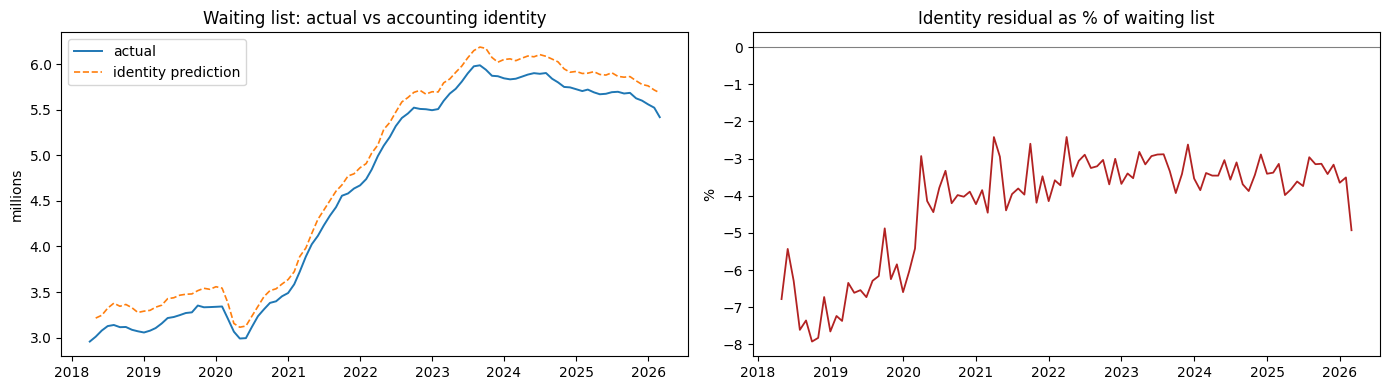

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(nat.index, nat.waiting / 1e6, lw=1.4, label="actual")
ax[0].plot(nat.index, nat.predicted / 1e6, lw=1.2, ls="--", label="identity prediction")
ax[0].set_title("Waiting list: actual vs accounting identity")
ax[0].set_ylabel("millions"); ax[0].legend()
ax[1].plot(nat.index, nat.residual_pct_list, lw=1.3, color="firebrick")
ax[1].axhline(0, color="grey", lw=0.8)                         # zero = the identity holds exactly
ax[1].set_title("Identity residual as % of waiting list")
ax[1].set_ylabel("%")
plt.tight_layout()

---

# The column contract

The raw return is 69 columns before April 2021 and 121 after. The canonical table keeps **14**. A column earns its place only if some part of the README's system consumes it; everything else is dropped, and the reason is measured here rather than asserted, so the contract can be re-checked if NHS England changes the return again.

## Kept, and what consumes it

| Column | Consumed by |
|---|---|
| `month`, `provider_code`, `dept` | the key — one series per federated client × department |
| `demand` (`Part_3`) | **the forecast target.** New RTT periods = new referrals |
| `completed_admitted`, `completed_nonadmitted` | trailing throughput, split because the README's capacity ask is in treatments per month, admitted vs non-admitted, never literal beds |
| `completed` | their sum; the throughput term in the accounting identity |
| `waiting` (`Part_2`) | backlog stock |
| `waiting_gt18` | the 18-week standard the agent projects against |
| `waiting_gt52` | breach severity — how far past the standard the queue already is |
| `waiting_dta` (`Part_2A`) | the bed-linked admission queue |
| `sector` | independents enter as purchasable substitution capacity, not as clients |
| `icb` | the escalation key: trust → ICB → national |
| `panel_member` | selects the 126 federation clients; a flag, never a filter |

## Dropped, with the measurement that justifies it

| Dropped | Why |
|---|---|
| `Total` | populated **only** for the two completed part types; identically zero for `Part_2`, `Part_2A` and `Part_3`. `Total All` is the only headline column populated for all five. |
| `Patients with unknown clock start date` | 0.006% of `Total All`, and already inside it. No decision turns on 6 patients in 100,000. |
| `Commissioner Org/Parent Code` + names | a *second* hierarchy — who pays — orthogonal to the README's provider → ICB → national escalation. Collapsing it is what turns ~145,000 raw rows per month into ~16,000 provider × dept × part groups, and Assert 1 passes *after* that collapse, so no provider-level information is lost. |
| `Provider Parent Name`, `Commissioner *Name`, `RTT Part Description`, `Treatment Function Name` | labels for codes already carried. F-11 proved the names are **unstable** across the 2021 break while the codes are not, so carrying them is an active hazard, not redundancy. |
| bands 0–18 weeks | within-standard waits. The operational state is the breach count, not the shape of the compliant queue. |
| bands on `Part_1A/1B/2A/3` | `Part_3` has **no** populated bands at all (F-03). For the completed parts the bands describe realised wait, which is a plausible future feature but is in no README state variable — dropped deliberately, recoverable from raw. |
| `provider_name` | one value per code, 30 MB of a 170 MB table. Moved to `provider_dim.csv`, where a per-provider attribute belongs. |
| `icb_reported`, `icb_ods` | superseded by the single resolved `icb`. Provenance kept in `provider_dim.csv`. |
| `in_roster` | exactly `dept != X_OTHER`. Two ways to express one fact is two ways to disagree. |

`completed` is kept although it is exactly `admitted + nonadmitted`: it is a measure the README names directly, and precomputing the model-facing quantity is the point of a canonical table. The rule is *drop derivable flags, keep derived measures*.

In [12]:
# Evidence for the drops. One file per era, read in full — the contract is a claim about
# every column, so this is the one place the discarded columns are actually looked at.
for label, p in [("pre-2021", csvs[0]), ("post-2021", csvs[-1])]:
    d = pd.read_csv(p, low_memory=False)                       # whole file, all 69 or 121 columns
    d = d[d["Treatment Function Code"] != AGG]                 # published aggregate rows are not data
    bands = [c for c in d.columns if "Weeks SUM" in c]         # every waiting-time band this era has
    d[bands] = d[bands].fillna(0)                              # a blank band means no patients
    d["bandsum"] = d[bands].sum(axis=1)                        # patients accounted for by the bands

    print(f"=== {label}: {p.name}")
    print(f"    {len(d.columns) - len(bands)} descriptive/headline columns + {len(bands)} bands")

    # (1) is 'Total' ever needed, or does 'Total All' carry everything?
    t = d.groupby("RTT Part Type")[["Total", "Total All", "bandsum"]].sum()
    t["Total/TotalAll"] = (t["Total"] / t["Total All"]).round(4)      # 0 = column is empty here
    t["bands/TotalAll"] = (t["bandsum"] / t["Total All"]).round(4)    # 0 = part type has no bands
    print(t.to_string(float_format=lambda v: f"{v:,.0f}"))

    # (2) how much sits in the unknown-clock-start column that we never read
    unk = d["Patients with unknown clock start date"].fillna(0)
    print(f"    unknown clock start: {unk.sum():,.0f} = "
          f"{100 * unk.sum() / d['Total All'].sum():.4f}% of Total All, and already inside it")

    # (3) what the commissioner axis costs. ngroups is the number of groups a groupby would
    #     produce without materialising them — the row count our build collapses to.
    g = d.groupby(["Provider Org Code", "Treatment Function Code", "RTT Part Type"]).ngroups
    print(f"    rows {len(d):,} -> provider x tf x part {g:,}  "
          f"(the commissioner axis is a {len(d) / g:.1f}x row multiplier)")
    print()

# (4) names are unstable, codes are not — why every join in this notebook is on code
n_pre = pd.read_csv(csvs[0], usecols=["Treatment Function Code", "Treatment Function Name"])
n_post = pd.read_csv(csvs[-1], usecols=["Treatment Function Code", "Treatment Function Name"])
name = lambda d: dict(zip(d["Treatment Function Code"], d["Treatment Function Name"]))
a, b = name(n_pre), name(n_post)
changed = [k for k in a if k in b and a[k] != b[k]]            # same code, different label
print(f"treatment function codes present in both eras : {len(set(a) & set(b))}")
print(f"  of those, RENAMED across the break          : {len(changed)}")
print(f"  example: {changed[0]} '{a[changed[0]]}' -> '{b[changed[0]]}'")

=== pre-2021: RTT-April-2018-full-extract-revised.csv
    17 descriptive/headline columns + 53 bands
                  Total  Total All   bandsum  Total/TotalAll  bands/TotalAll
RTT Part Type                                                               
Part_1A         286,943     287031   286,943               1               1
Part_1B       1,006,862    1007247 1,006,862               1               1
Part_2                0    4037223 4,037,223               0               1
Part_2A               0     750564   750,564               0               1
Part_3                0    1646372         0               0               0
    unknown clock start: 473 = 0.0061% of Total All, and already inside it
    rows 151,746 -> provider x tf x part 15,762  (the commissioner axis is a 9.6x row multiplier)



/tmp/ipykernel_2978543/1066691469.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d["bandsum"] = d[bands].sum(axis=1)                        # patients accounted for by the bands


=== post-2021: 20260331-RTT-March-2026-full-extract-revised.csv
    17 descriptive/headline columns + 105 bands
                  Total  Total All   bandsum  Total/TotalAll  bands/TotalAll
RTT Part Type                                                               
Part_1A         320,415     320541   320,415               1               1
Part_1B       1,374,620    1375272 1,374,620               1               1
Part_2                0    7045510 7,045,510               0               1
Part_2A               0    1178492 1,178,492               0               1
Part_3                0    1932318         0               0               0
    unknown clock start: 778 = 0.0066% of Total All, and already inside it
    rows 143,342 -> provider x tf x part 16,363  (the commissioner axis is a 8.8x row multiplier)



treatment function codes present in both eras : 19
  of those, RENAMED across the break          : 18
  example: C_100 'General Surgery' -> 'General Surgery Service'


## Why `icb_reported` cannot be the escalation key

The RTT file states a `Provider Parent Org Code`, and it is tempting to treat it as the trust's ICB. It is not: it is whatever parent existed *that month*, and the parent organisation of an English trust changed identity twice inside our window — regions until 2019, STPs/ICSs from 2020, statutory ICBs from July 2022.

The test is agreement against `icb_ods`, the parent resolved from the ODS `RE5` "is commissioned by" relationship, which is a single present-day value per trust. If the reported parent were an ICB throughout, agreement would be near 100% in every year.

In [13]:
# only public providers have both columns — independents have no ODS commissioner parent
both = icb_audit.dropna(subset=["icb_ods"])
# .dt.to_period("Y") turns a timestamp into a year-granularity period, so all months of a
# year collapse into one grouping key without any string formatting
yr = both.groupby(both.month.dt.to_period("Y")).apply(
    lambda d: pd.Series({
        "rows": len(d),
        "distinct_reported": d.icb_reported.nunique(),           # 14 = regions, 42 = ICBs
        "agree_with_ods_pct": round((d.icb_reported == d.icb_ods).mean() * 100, 1),
    }), include_groups=False)                                    # exclude the key from the lambda's frame
print(yr.to_string())
print()
print("2018-19: 14 distinct parents, 0% agreement — the reported parent is an NHS REGION,")
print("a different level of the hierarchy entirely. From 2020 it is 42 ICBs agreeing ~74%;")
print("the residual 26% is real drift between the file and ODS. Neither era is safe as a key,")
print("so `icb` comes from ODS and is backfilled only where ODS has no answer.")
print()
print(f"resolved icb: {canon.icb.nunique()} distinct | "
      f"panel trusts covered {canon[canon.panel_member].icb.notna().mean() * 100:.0f}%")

          rows  distinct_reported  agree_with_ods_pct
month                                                
2018   19205.0               14.0                 0.0
2019   25971.0               14.0                 0.0
2020   25981.0               56.0                56.2
2021   25815.0               42.0                74.2
2022   25610.0               42.0                73.8
2023   25548.0               42.0                72.8
2024   25098.0               42.0                72.8
2025   24630.0               42.0                73.8
2026    6124.0               42.0                74.1

2018-19: 14 distinct parents, 0% agreement — the reported parent is an NHS REGION,
a different level of the hierarchy entirely. From 2020 it is 42 ICBs agreeing ~74%;
the residual 26% is real drift between the file and ODS. Neither era is safe as a key,
so `icb` comes from ODS and is backfilled only where ODS has no answer.

resolved icb: 47 distinct | panel trusts covered 100%


---

# Write the outputs

The 96 monthly extracts, 7.7 GB of raw CSV, collapse to **one** RTT table on the contract above.

| File | What it is |
|---|---|
| `rtt_canonical.parquet` | **the merged RTT table** — every provider × department × month, 14 columns |
| `rtt_canonical.csv.gz` | the same table as text, for anything that cannot read parquet |
| `rtt_panel.parquet` | the rectangular 126 × 19 × 96 federation cube |
| `provider_dim.csv` | one row per provider: name, sector, ICB, panel membership, ICB provenance |
| `national_monthly.csv` | national series plus the accounting-identity residual |

Parquet is the primary format because it stores column types and compresses each column separately, so `month` comes back as a datetime rather than a string and the file is a fraction of the CSV size. The gzipped CSV is a convenience copy, not the source of truth.

In [14]:
canon.to_parquet(OUT / "rtt_canonical.parquet", index=False)   # the merged RTT table
panel.to_parquet(OUT / "rtt_panel.parquet", index=False)       # rectangular 126 x 19 x 96 cube
provider_dim.to_csv(OUT / "provider_dim.csv", index=False)     # per-provider attributes
nat.to_csv(OUT / "national_monthly.csv")                       # national series + identity check
# compression is inferred from the .gz suffix; the text copy exists only for tools that
# cannot read parquet, and is roughly an order of magnitude larger before compression
canon.to_csv(OUT / "rtt_canonical.csv.gz", index=False)

raw_bytes = sum(f.stat().st_size for f in csvs)                # the 96 source extracts
for f in sorted(OUT.glob("*")):
    print(f"{f.name:26s} {f.stat().st_size / 1e6:8.1f} MB")
print(f"\n{len(csvs)} raw extracts {raw_bytes / 1e9:.1f} GB -> one table "
      f"{(OUT / 'rtt_canonical.parquet').stat().st_size / 1e6:.1f} MB "
      f"({raw_bytes / (OUT / 'rtt_canonical.parquet').stat().st_size:,.0f}x smaller)")

print("\ncanonical schema:")
print(canon.dtypes.to_string())

# read the parquet straight back: a written file that cannot be read is not an output
check = pd.read_parquet(OUT / "rtt_canonical.parquet")
assert check.shape == canon.shape, "round-trip changed the table's shape"
assert check.month.dtype.kind == "M", "month did not survive as a datetime"   # 'M' = datetime64
print(f"\nround-trip OK: {check.shape[0]:,} x {check.shape[1]} columns, "
      f"months {check.month.min():%Y-%m} to {check.month.max():%Y-%m}")

national_monthly.csv            0.0 MB
provider_dim.csv                0.1 MB
rtt_canonical.csv.gz            5.1 MB
rtt_canonical.parquet           3.7 MB
rtt_panel.parquet               2.1 MB

96 raw extracts 8.2 GB -> one table 3.7 MB (2,221x smaller)

canonical schema:
month                    datetime64[us]
provider_code                    object
dept                             object
sector                           object
icb                              object
panel_member                       bool
demand                          float64
completed_admitted              float64
completed_nonadmitted           float64
completed                       float64
waiting                         float64
waiting_gt18                    float64
waiting_gt52                    float64
waiting_dta                     float64

round-trip OK: 322,531 x 14 columns, months 2018-04 to 2026-03
